# Multi-Agent Credit Committee & Fraud Detection System
#### Generative AI Final Project
#### Workflow
#### Foundations
* Libraries & Setup
* Banking State Definition
* LLM Configuration
#### Agents & Nodes
1. Sentiment / Front-Desk Node
2. Fraud & Risk Agent Node (Tool Caller)
3. Compliance Agent Node (RAG)
4. Supervisor / Judge Node (Decision Maker)
5. Human Escalation Node
#### Graph
#### Test Scenarios
1. Scenario 1: Good Standing Customer & Loan Approval
2. Scenario 2: Angry Customer & Human Intervention

# Foundation

## Library

In [2]:
import operator
import json
import re
from typing import Literal, Optional, TypedDict, Annotated
from pydantic import BaseModel, Field
from langchain_community.document_loaders import TextLoader

from langchain_core.messages import BaseMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.tools import tool
from langchain_core.documents import Document

from langchain_ollama import ChatOllama
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, START, END, add_messages
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Image, display

C:\Users\Asus\AppData\Local\Temp\ipykernel_184992\1899087337.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


## LLM

In [ ]:
llm = ChatOllama(model="qwen2.5:7b", temperature=0)

## Banking State

In [4]:
class BankingState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]  # مدیریت استاندارد لیست پیام‌ها
    customer_id: Optional[str]        # کد ملی ۱۰ رقمی مشتری
    loan_request: Optional[str]       # نوع و مبلغ وام درخواستی
    sentiment: str                    # وضعیت احساسی کاربر (Normal یا Angry)
    sentiment_reasoning: str          # استدلال مدل برای تشخیص لحن
    risk_report: dict                 # خروجی استعلامات مالی و پرچم‌های خطر
    compliance_check: str             # نتیجه بررسی بخشنامه‌ها از طریق RAG
    final_decision: dict              # خروجی نهایی ساختاریافته (JSON)
    response_message: str             # پیام نهایی به مشتری

# Node

## 1.Sentiment Node

#### 1.Structure Output

In [ ]:
class SentimentDecision(BaseModel):
  reasoning: str = Field(
      description=(
          "تحلیل گام‌به‌گام کوتاه برای تشخیص لحن مشتری و استخراج اطلاعات"
          " کلیدی از متن."))

  sentiment: Literal["Normal", "Angry"] = Field(
      description=(
          "لحن احساسی مشتری. مقادیر مجاز: 'Normal' برای لحن عادی، محترمانه یا"
          " آرام، و 'Angry' برای لحن عصبانی، معترض، طلبکارانه یا ناراضی."))

  customer_id: Optional[str] = Field(
      default=None,
      description=("کد ملی ۱۰ رقمی مشتری در صورت وجود در متن، در غیر این صورت None."),)

  loan_request: Optional[str] = Field(
      default=None,
      description=("نوع و مبلغ وام درخواستی استخراج‌شده از متن مشتری، در غیر این صورت"
                   " None."))

#### 2.Prompt

In [6]:
from langchain_core.prompts import ChatPromptTemplate

sentiment_prompt = ChatPromptTemplate.from_messages([
    ("system", """شما یک عامل هوشمند در بخش پذیرش و تریاژ اولیه بانک هستید.

### نقش و هدف:
وظیفه شما تحلیل پیام‌های متنی مشتریان، تشخیص لحن/احساسات آن‌ها و استخراج دقیق اطلاعات کلیدی است.

### دستورالعمل‌ها:

۱. **ارزیابی لحن و احساسات (Sentiment)**:
   - **'Angry' (عصبانی)**: تنها زمانی این حالت را انتخاب کنید که مشتری صراحتاً دارای خشم، پرخاشگری، توهین، یا شکایت شدید از تاخیرها و خدمات نامناسب بانک باشد.
   - **'Normal' (عادی)**: برای تمامی درخواست‌های رسمی وام، تقاضاها، سوالات عمومی یا پیگیری‌های محترمانه این حالت را انتخاب کنید (حتی اگر درخواست مبالغ بالا باشد یا لحن جدی داشته باشد). درخواست دریافت وام به هیچ وجه نباید عصبانی (`Angry`) تلقی شود.

۲. **استخراج کد ملی (`customer_id`)**:
   - به دنبال یک کد ۱۰ رقمی مربوط به کد ملی بگردید.
   - ارقام فارسی یا عربی (مانند ۱۲۳۴۵۶۷۸۹۰) را به ارقام انگلیسی استاندارد (1234567890) تبدیل کنید.
   - در صورت عدم وجود، مقدار `null` برگردانید.

۳. **خلاصه درخواست وام (`loan_request`)**:
   - نوع و مبلغ وام درخواستی را به صورت خلاصه و دقیق استخراج کنید. در صورت عدم ذکر، مقدار `null` برگردانید.

### نمونه مثال‌ها (Few-Shot Examples):
- پیام مشتری: "من برای توسعه کسب‌وکارم ۵۰۰ میلیون تومان وام خرید تجهیزات می‌‌خوام. کد ملی: ۱۲۳۴۵۶۷۸۹۰"
  <- لحن: Normal | کد ملی: 1234567890 | خلاصه درخواست: ۵۰۰ میلیون تومان وام خرید تجهیزات

- پیام مشتری: "چرا وام من رو نمیدید؟ یک ماهه معطلم کردید، واقعاً خسته شدم از این بانک!"
  <- لحن: Angry | کد ملی: null | خلاصه درخواست: null

- پیام مشتری: "سلام، شرایط دریافت وام ودیعه مسکن چیه؟ ۱۲۳۴۵۶۷۸۹۰"
  <- لحن: Normal | کد ملی: 1234567890 | خلاصه درخواست: وام ودیعه مسکن
"""),
    ("human", "پیام مشتری:\n{user_message}")
])

#### 3.Agent

In [ ]:
sentiment_chain = sentiment_prompt | llm.with_structured_output(SentimentDecision)

def sentiment_agent(state: BankingState):
    last_user_message = state["messages"][-1].content
    
    result: SentimentDecision = sentiment_chain.invoke({"user_message": last_user_message})

    return {"sentiment": result.sentiment,
            "sentiment_reasoning": result.reasoning,
            "customer_id": result.customer_id or state.get("customer_id"),
            "loan_request": result.loan_request or state.get("loan_request")}

#### 4.Router

In [ ]:
def route_after_sentiment(state: BankingState) -> Literal["human_escalation", "fraud_agent"]:
    """مسیریاب شرطی گراف"""
    if state.get("sentiment") == "Angry":
        return "human_escalation"
    return "fraud_agent"

## 2.Fraud Node (Tool Caller)

#### 1.Tool

In [ ]:
# ۱. تعریف ابزار شبیه‌سازی شده استعلام بانکی
@tool
def check_banking_records(customer_id: str):
    """استعلام سوابق اعتباری، بانکی و مدارک شغلی مشتری."""
    
    mock_database = {
        # مشتری ۱: خوش‌حساب با پروانه کسب معتبر
        "1234567890": {
            "bounced_checks": 0,
            "current_debt": 0,
            "blacklisted": False,
            "credit_score": 800,
            "has_business_license": True,   # دارای پروانه کسب معتبر
            "provided_documents": ["پروانه کسب", "سفته"]
        },
        # مشتری ۲: بدحساب و بدون پروانه کسب
        "9876543210": {
            "bounced_checks": 4,
            "current_debt": 200000000,
            "blacklisted": True,
            "credit_score": 420,
            "has_business_license": False,  # فاقد پروانه کسب
            "provided_documents": []
        }
    }
    
    # مقدار پیش‌فرض برای سایر کد‌های ملی
    default_record = {
        "bounced_checks": 0,
        "current_debt": 0,
        "blacklisted": False,
        "credit_score": 650,
        "has_business_license": False,
        "provided_documents": []
    }
    
    return mock_database.get(customer_id, default_record)

#### 2.Agent

In [10]:
def fraud_agent(state: BankingState):
    customer_id = state.get("customer_id") or "1234567890"
    
    tool_result = check_banking_records.invoke({"customer_id": customer_id})
    
    red_flags = []
    if tool_result["bounced_checks"] > 0: 
        red_flags.append(f"دارای {tool_result['bounced_checks']} چک برگشتی")

    if tool_result["blacklisted"]: 
        red_flags.append("قرار داشتن در لیست سیاه بانک")

    if tool_result["credit_score"] < 600: 
        red_flags.append("نمره اعتبار پایین")

    # if len(red_flags) == 0:
    #     red_flags.append("هیچ پرچم خطری یافت نشد")

    risk_report = {
        "credit_score": tool_result["credit_score"],
        "bounced_checks": tool_result["bounced_checks"],
        "blacklisted": tool_result["blacklisted"],
        "red_flags": red_flags if red_flags else ["هیچ پرچم خطری یافت نشد"]}
    
    
    return {"risk_report": risk_report}

## 3.Compliance Node (RAG)

#### 1.RAG

* Documents

In [ ]:
circular_docs = []

circular_docs.extend(TextLoader("circulars/circular_equipment_loan.txt", encoding="utf-8").load())
circular_docs.extend(TextLoader("circulars/circular_housing_loan.txt", encoding="utf-8").load())
circular_docs.extend(TextLoader("circulars/circular_general_rules.txt", encoding="utf-8").load())

* Embeddings

In [13]:
embeddings = HuggingFaceEmbeddings(
    model_name="intfloat/multilingual-e5-base",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

* Vector Store

In [14]:
vectorstore = FAISS.from_documents(circular_docs, embeddings)

* Retriever

In [15]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

#### 2.Prompt

In [16]:
compliance_prompt = ChatPromptTemplate.from_messages([
    ("system", """شما ارزیاب ارشد تطبیق مقررات و بخشنامه‌های بانکی هستید.

### نقش و هدف:
وظیفه شما بررسی دقیق درخواست وام مشتری انحصاراتً بر اساس بخشنامه‌ها و دستورالعمل‌های ارائه‌شده (`context`) و تعیین میزان انطباق قانونی، وثایق مورد نیاز و شروط اعطای تسهیلات است.

### قوانین و محدودیت‌های اصلی:
۱. **استناد کامل به متن (جلوگیری از توهم)**: تنها و انحصاراتً بر اساس اطلاعات موجود در `{context}` پاسخ دهید. از حدس زدن، فرض کردن یا وارد کردن قوانین بانکی خارج از متن بخشنامه‌ها جداً خودداری کنید.
۲. **عدم وجود بخشنامه مرتبط**: اگر در `{context}` بخشنامه‌ای مرتبط با درخواست مشتری وجود ندارد، به صراحت اعلام کنید: «بخشنامه مرتبطی در پایگاه داده یافت نشد».
۳. **لحن و ساختار**: پاسخ باید کاملاً صریح، کارشناسی، بدون حاشیه‌پردازی و طبق ساختار تعیین‌شده زیر باشد.

### فرمت الزامی خروجی:
پاسخ خود را دقیقاً در قالب زیر تنظیم کنید:
- **وضعیت انطباق**: [مجاز / غیرمجاز / نیازمند بررسی تکمیلی]
- **سقف مجاز تسهیلات**: [مبلغ مشخص‌شده در بخشنامه یا «در بخشنامه ذکر نشده»]
- **وثایق و تضامین لازم**: [فهرست وثایق مانند سفته، ضامن رسمی، کسر از حقوق و...]
- **شروط اصلی اعطا**: [شرایط قانونی مانند ارائه پروانه کسب، نداشتن چک برگشتی و...]"""),
    ("human", """درخواست مشتری:
{loan_request}

بخشنامه‌های مرتبط:
{context}

لطفاً ارزیابی انطباق حقوقی را طبق فرمت مشخص‌شده ارائه دهید:""")
])

#### 3. Agent

In [ ]:
compliance_chain = compliance_prompt | llm

def compliance_agent(state: BankingState):
    loan_request = state.get("loan_request") or "وام خرید تجهیزات"
    

    search_query = f"query: {loan_request}"
    relevant_docs = retriever.invoke(search_query)
    
    context = "\n---\n".join([doc.page_content for doc in relevant_docs])
    
   
    print("\n[DEBUG] متن بخشنامه بازیابی شده:\n", context)
    

    response = compliance_chain.invoke({"loan_request": loan_request,
                                        "context": context})
    
    return {"compliance_check": response}

## 4.Judge Node (Decision Maker)

#### 1.Structure Output

In [ ]:
class FinalDecisionSchema(BaseModel):
    status: Literal["Approved", "Rejected"] = Field(description="وضعیت نهایی درخواست: Approved یا Rejected")
    max_amount: str = Field(description="سقف مبلغ مجاز وام به ریال یا تومان")
    collateral: str = Field(description="وثایق و مدارک مورد نیاز")
    reason: str = Field(description="دلیل تصمیم نهایی کمیته اعتباری")

#### 2.Prompt

In [19]:
judge_prompt = ChatPromptTemplate.from_messages([
    ("system", """شما رئیس کمیته اعطای تسهیلات و اعتبارات بانک هستید.

### نقش و مسئولیت:
وظیفه شما اتخاذ تصمیم نهایی و قاطع (Approved یا Rejected) در مورد درخواست وام مشتری، با تلفیق «گزارش ریسک مالی» و «ارزیابی انطباق مقررات» است.

### ماتریس و قوانین تصمیم‌گیری:
۱. **قانون رد خودکار (Rejected)**:
   - اگر مشتری در لیست سیاه باشد (`blacklisted: true`)، درخواست **بلافاصله رد می‌شود**.
   - اگر مشتری دارای چک برگشتی باشد (`bounced_checks > 0`)، درخواست **بلافاصله رد می‌شود**.
   - اگر ارزیابی حقوقی، درخواست را «غیرمجاز» دانسته باشد، درخواست **بلافاصله رد می‌شود**.
۲. **شرایط تایید (Approved)**:
   - درخواست تنها زمانی تایید می‌شود که هیچ پرچم قرمز مالی (چک برگشتی/لیست سیاه) وجود نداشته باشد و بررسی حقوقی نیز انطباق کامل با بخشنامه‌ها را تایید کرده باشد.
۳. **استخراج اطلاعات**:
   - سقف مبلغ و وثایق درخواستی را مستقیماً از گزارش حقوقی استخراج کنید و از خود مبلغی اضافه نکنید.

### راهنمای فیلدهای خروجی ساختاریافته:
- **status**: دقیقاً یکی از دو مقدار 'Approved' یا 'Rejected'.
- **max_amount**: سقف مبلغ مصوب به تومان/ریال (در صورت رد شدن «۰ تومان»).
- **collateral**: وثایق و تضامین لازم طبق گزارش حقوقی (در صورت رد شدن «هیچ»).
- **reason**: توضیحات صریح و کارشناسی به فارسی درباره علت دقیق تایید یا رد درخواست مستند به شواهد."""),
    ("human", """درخواست وام مشتری:
{loan_request}

گزارش ریسک مالی:
{risk_report}

بررسی انطباق مقررات (RAG):
{compliance_check}

لطفاً ارزیابی نهایی را انجام داده و تصمیم را صادر کنید:""")
])

#### 3.Agent

In [20]:
# زنجیره LCEL قاضی نهایی با Structured Output
judge_chain = judge_prompt | llm.with_structured_output(FinalDecisionSchema)

def judge_agent(state: BankingState):
    # اجرای زنجیره LCEL
    decision: FinalDecisionSchema = judge_chain.invoke({"loan_request": state.get("loan_request", ""),
                                                        "risk_report": json.dumps(state.get("risk_report", {}), ensure_ascii=False),
                                                        "compliance_check": state.get("compliance_check", "")})
    
    final_dict = {"status": decision.status,
                  "max_amount": decision.max_amount,
                  "collateral": decision.collateral,
                  "reason": decision.reason}
    
    return {"final_decision": final_dict,
            "response_message": f"درخواست شما با وضعیت {decision.status} پردازش شد."}

## 5.Human Node

In [ ]:
def human_escalation_node(state: BankingState):
    
    message = "مشتری گرامی، از تاخیر پیش آمده پوزش می‌‌طلبیم. درخواست شما مستقیماً به مدیر شعبه ارجاع داده شد."
    
    return {"response_message": message,
            "final_decision": {"status": "رجاع به کارشناس انسانی",
                               "reason": "شناسایی لحن معترض یا عصبانی مشتری در مرحله ورودی (سنجش احساسات)"}}

# Graph

#### 1.Node

In [ ]:
builder = StateGraph(BankingState)

builder.add_node("sentiment_agent", sentiment_agent)
builder.add_node("fraud_agent", fraud_agent)
builder.add_node("compliance_agent", compliance_agent)
builder.add_node("judge_agent", judge_agent)
builder.add_node("human_escalation", human_escalation_node)

#### 2.Conection

In [ ]:
builder.add_edge(START, "sentiment_agent")

builder.add_conditional_edges("sentiment_agent", route_after_sentiment,{"human_escalation": "human_escalation",
                                                                        "fraud_agent": "fraud_agent"})

builder.add_edge("fraud_agent", "compliance_agent")
builder.add_edge("compliance_agent", "judge_agent")
builder.add_edge("judge_agent", END)
builder.add_edge("human_escalation", END)

#### 3.Compile

In [24]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

#### 4.Draw Graph

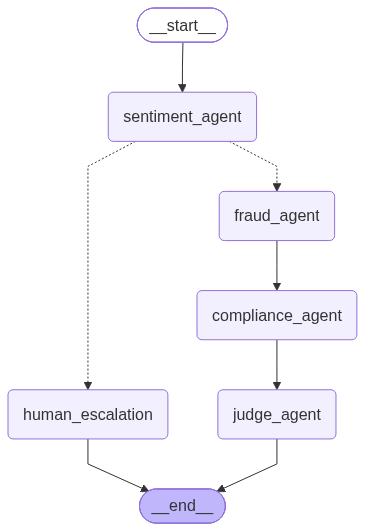

In [25]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print("امکان نمایش تصویر گراف وجود ندارد.")

# Tset

####  --- سناریوی اول: مشتری خوش‌حساب ---

In [ ]:
print("\n================== سناریوی اول: مشتری خوش‌حساب ==================")

initial_state_1 = {
    "messages": [
        HumanMessage(content="من برای توسعه کسب‌وکارم ۵۰۰ میلیون تومان وام خرید تجهیزات می‌خوام. پروانه کسب معتبر دارم و سفته هم می‌تونم بدم. کد ملی: 1234567890")
    ]
}

config_1 = {"configurable": {"thread_id": "scenario_1"}}

for output in graph.stream(initial_state_1, config=config_1):
    for node_name, updated_state in output.items():
        print(f"\n--- گره اجرا شده: {node_name} ---")
        for key, value in updated_state.items():
            print(f"  {key}: {value}")

print("\n---------------- خروجی نهایی ساختاریافته (JSON) ----------------")
final_state_1 = graph.get_state(config_1).values
print(json.dumps(final_state_1.get("final_decision", {}), ensure_ascii=False, indent=2))


================== سناریوی اول: مشتری خوش‌حساب ==================

--- گره اجرا شده: sentiment_agent ---
  sentiment: Normal
  sentiment_reasoning: مشتری درخواست وام ۵۰۰ میلیون تومان برای توسعه کسب‌وکارش دارد. لحن پیام عادی است و مشخصات مورد نیاز وجود دارد.
  customer_id: 1234567890
  loan_request: ۵۰۰ میلیون تومان وام خرید تجهیزات

--- گره اجرا شده: fraud_agent ---
  risk_report: {'credit_score': 800, 'bounced_checks': 0, 'blacklisted': False, 'red_flags': ['هیچ پرچم خطری یافت نشد']}

[DEBUG] متن بخشنامه بازیابی شده:
 طبق بخشنامه جدید بانک مرکزی، وام خرید تجهیزات و توسعه کسب‌وکار تا سقف ۵۰۰ میلیون تومان نیازمند ارائه پروانه کسب معتبر و سفته به عنوان وثیقه می‌باشد
---
طبق بخشنامه جدید، وام ودیعه مسکن نیازمند دو ضامن رسمی و کسر از حقوق می‌باشد و حداکثر سقف آن ۲۰۰ میلیون تومان است

--- گره اجرا شده: compliance_agent ---
  compliance_check: content='- **وضعیت انطباق**: مجاز\n- **سقف مجاز تسهیلات**: ۵۰۰ میلیون تومان\n- **وثایق و تضامین لازم**: پروانه کسب معتبر و سفته\n- **شروط اصلی اعطا**

#### --- سناریوی دوم: مشتری عصبانی / مداخله انسانی ---

In [27]:
print("\n================== سناریوی دوم: مشتری ناراضی / لحن عصبانی ==================")

initial_state_2 = {
    "messages": [
        HumanMessage(content="چرا وام من رو نمیدید؟ من یک ماهه تو صف هستم و واقعا از سرویس‌دهی بانک خسته شدم!")
    ]
}

config_2 = {"configurable": {"thread_id": "scenario_2"}}

for output in graph.stream(initial_state_2, config=config_2):
    for node_name, updated_state in output.items():
        print(f"\n--- گره اجرا شده: {node_name} ---")
        for key, value in updated_state.items():
            print(f"  {key}: {value}")

print("\n---------------- خروجی نهایی به کاربر ----------------")
final_state_2 = graph.get_state(config_2).values
print("پاسخ سیستم به کاربر:", final_state_2.get("response_message"))
print("وضعیت پرونده:", json.dumps(final_state_2.get("final_decision", {}), ensure_ascii=False, indent=2))


================== سناریوی دوم: مشتری ناراضی / لحن عصبانی ==================



--- گره اجرا شده: sentiment_agent ---
  sentiment: Angry
  sentiment_reasoning: مشتری عصبانی است زیرا صراحتاً خستگی و پرخاشگری را نشان می‌دهد.
  customer_id: None
  loan_request: None

--- گره اجرا شده: human_escalation ---
  response_message: مشتری گرامی، از تاخیر پیش آمده پوزش می‌‌طلبیم. درخواست شما مستقیماً به مدیر شعبه ارجاع داده شد.
  final_decision: {'status': 'Escalated to Human Operator', 'reason': 'Dissatisfied tone / Angry sentiment detected at front-desk'}

---------------- خروجی نهایی به کاربر ----------------
پاسخ سیستم به کاربر: مشتری گرامی، از تاخیر پیش آمده پوزش می‌‌طلبیم. درخواست شما مستقیماً به مدیر شعبه ارجاع داده شد.
وضعیت پرونده: {
  "status": "Escalated to Human Operator",
  "reason": "Dissatisfied tone / Angry sentiment detected at front-desk"
}


## Output function

In [28]:
import json
from langchain_core.messages import HumanMessage


def test_banking_scenario(
    scenario_name: str, user_message: str, thread_id: str
):
  """تابع کمکی برای اجرای استریم و ارزیابی سناریوهای مختلف در LangGraph."""
  print(f"\n================== {scenario_name} ==================")

  initial_state = {"messages": [HumanMessage(content=user_message)]}

  config = {"configurable": {"thread_id": thread_id}}

  # اجرای گراف و مشاهده خروجی لحظه‌ای هر گره
  for output in graph.stream(initial_state, config=config):
    for node_name, updated_state in output.items():
      print(f"\n--- 🟢 گره اجرا شده: {node_name} ---")
      for key, value in updated_state.items():
        print(f"  🔹 {key}: {value}")

  # دریافت وضعیت نهایی حافظه گراف
  final_state = graph.get_state(config).values
  final_decision = final_state.get("final_decision", {})
  response_message = final_state.get("response_message", "")

  print("\n---------------- 📊 خروجی نهایی سیستم ----------------")
  print(f"💬 پاسخ سیستم به کاربر: {response_message}")
  print("📋 وضعیت پرونده (JSON):")
  print(
      json.dumps(final_decision, ensure_ascii=False, indent=2)
      if final_decision
      else "مشخص نشده"
  )
  print("=" * 60)

  return final_state

In [29]:
# ۱. تست مسیر موفق (Happy Path)
test_banking_scenario(
    scenario_name="سناریوی اول: مشتری خوش‌حساب",
    user_message=(
        "من برای توسعه کسب‌وکارم ۵۰۰ میلیون تومان وام خرید تجهیزات می‌خوام."
        " پروانه کسب معتبر دارم و سفته هم می‌تونم بدم. کد ملی: 1234567890"
    ),
    thread_id="test_happy_path",
)

# ۲. تست ارجاع به اپراتور انسانی (Human Escalation)
test_banking_scenario(
    scenario_name="سناریوی دوم: مشتری عصبانی",
    user_message=(
        "چرا وام من رو نمیدید؟ من یک ماهه تو صف هستم و واقعا خسته شدم!"
    ),
    thread_id="test_angry_customer",
)

# ۳. تست رد درخواست به دلیل چک برگشتی / ریسک بالا (Fraud Rejection)
test_banking_scenario(
    scenario_name="سناریوی سوم: مشتری پرریسک",
    user_message=(
        "سلام، تقاضای ۵۰۰ میلیون تومان وام خرید تجهیزات دارم. کد ملی:"
        " 9876543210"
    ),
    thread_id="test_high_risk",
)

# ۴. تست رد درخواست به دلیل عدم انطباق با بخشنامه (Non-Compliant)
test_banking_scenario(
    scenario_name="سناریوی چهارم: درخواست غیرمجاز با بخشنامه",
    user_message=(
        "سلام، تقاضای ۱ میلیارد تومان وام خرید تجهیزات بدون پروانه کسب دارم."
        " کد ملی: 1234567890"
    ),
    thread_id="test_over_limit",
)


================== سناریوی اول: مشتری خوش‌حساب ==================

--- 🟢 گره اجرا شده: sentiment_agent ---
  🔹 sentiment: Normal
  🔹 sentiment_reasoning: مشتری درخواست وام ۵۰۰ میلیون تومان برای توسعه کسب‌وکارش دارد. لحن پیام عادی است و مشخصات مورد نیاز وجود دارد.
  🔹 customer_id: 1234567890
  🔹 loan_request: ۵۰۰ میلیون تومان وام خرید تجهیزات

--- 🟢 گره اجرا شده: fraud_agent ---
  🔹 risk_report: {'credit_score': 800, 'bounced_checks': 0, 'blacklisted': False, 'red_flags': ['هیچ پرچم خطری یافت نشد']}

[DEBUG] متن بخشنامه بازیابی شده:
 طبق بخشنامه جدید بانک مرکزی، وام خرید تجهیزات و توسعه کسب‌وکار تا سقف ۵۰۰ میلیون تومان نیازمند ارائه پروانه کسب معتبر و سفته به عنوان وثیقه می‌باشد
---
طبق بخشنامه جدید، وام ودیعه مسکن نیازمند دو ضامن رسمی و کسر از حقوق می‌باشد و حداکثر سقف آن ۲۰۰ میلیون تومان است

--- 🟢 گره اجرا شده: compliance_agent ---
  🔹 compliance_check: content='- **وضعیت انطباق**: مجاز\n- **سقف مجاز تسهیلات**: ۵۰۰ میلیون تومان\n- **وثایق و تضامین لازم**: پروانه کسب معتبر و سفته\n- 

{'messages': [HumanMessage(content='سلام، تقاضای ۱ میلیارد تومان وام خرید تجهیزات بدون پروانه کسب دارم. کد ملی: 1234567890', additional_kwargs={}, response_metadata={}, id='93b237d1-0a5c-40f3-bedb-5a1b4920d032')],
 'customer_id': '1234567890',
 'loan_request': '۱ میلیارد تومان وام خرید تجهیزات بدون پروانه کسب دار',
 'sentiment': 'Normal',
 'sentiment_reasoning': 'مشتری درخواست یک وام بزرگ (۱ میلیارد تومان) برای خرید تجهیزات بدون نیاز به پروانه کسب دارا است. لحن پیام عادی است.',
 'risk_report': {'credit_score': 800,
  'bounced_checks': 0,
  'blacklisted': False,
  'red_flags': ['هیچ پرچم خطری یافت نشد']},
 'compliance_check': AIMessage(content='- **وضعیت انطباق**: غیرمجاز\n- **سقف مجاز تسهیلات**: در بخشنامه ذکر نشده\n- **وثایق و تضامین لازم**: پروانه کسب معتبر و سفته\n- **شروط اصلی اعطا**: نیازمند ارائه پروانه کسب معتبر و سفته به عنوان وثیقه', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-10-07T11:48:14.2313962Z', 'done': True, 'done_reason': 'stop'